In [ ]:
# CCS 3209: Multimedia Systems
## Week 2 Laboratory Work
### Digital Audio Signal Processing, Image/Video Processing and Basic Digital Audio Synthesis

# Part A: Digital Audio Generation and Analysis

## Activity A1: Generate a Sampled Sine Wave

Number of samples: 88200
Maximum amplitude: 0.24999993656447184
Minimum amplitude: -0.24999993656447175


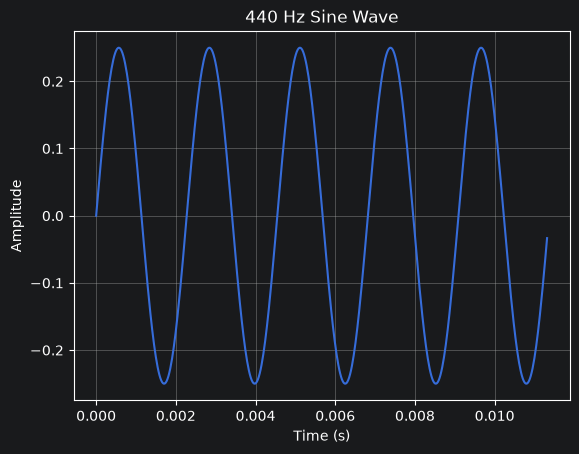

In [3]:
import numpy as np
import matplotlib.pyplot as plt

fs = 44100
duration = 2
frequency = 440
amplitude = 0.25

t = np.arange(int(fs * duration)) / fs
x = amplitude * np.sin(2 * np.pi * frequency * t)

print("Number of samples:", len(x))
print("Maximum amplitude:", np.max(x))
print("Minimum amplitude:", np.min(x))

plt.plot(t[:500], x[:500])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("440 Hz Sine Wave")
plt.grid(True)
plt.show()

In [4]:
for fs_test in [8000, 22050, 44100]:
    t_test = np.arange(fs_test) / fs_test
    signal = 0.5 * np.sin(2 * np.pi * 440 * t_test)
    print(fs_test, "Hz ->", len(signal), "samples")

8000 Hz -> 8000 samples
22050 Hz -> 22050 samples
44100 Hz -> 44100 samples


# PART B: Digital Audio Processing
## Activity B1: Amplitude Scaling and Clipping

In [5]:
fs = 44100
t = np.arange(fs) / fs
x = 0.5 * np.sin(2 * np.pi * 440 * t)

quiet = 0.5 * x
louder = 1.5 * x

print("Original peak:", np.max(np.abs(x)))
print("Quiet peak:", np.max(np.abs(quiet)))
print("Louder peak:", np.max(np.abs(louder)))

Original peak: 0.49999987312894345
Quiet peak: 0.24999993656447173
Louder peak: 0.7499998096934152


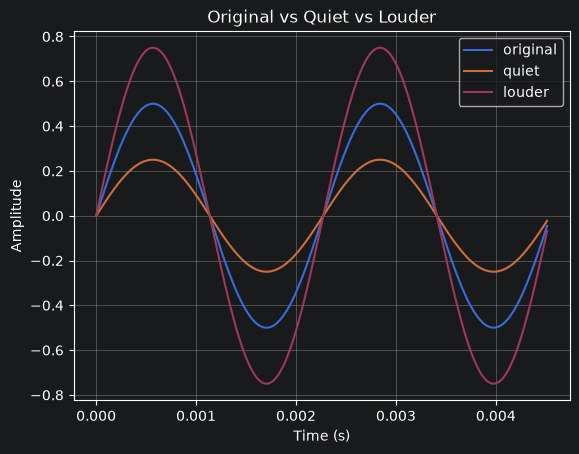

In [6]:
plt.plot(t[:200], x[:200], label="original")
plt.plot(t[:200], quiet[:200], label="quiet")
plt.plot(t[:200], louder[:200], label="louder")
plt.legend()
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Original vs Quiet vs Louder")
plt.grid(True)
plt.show()

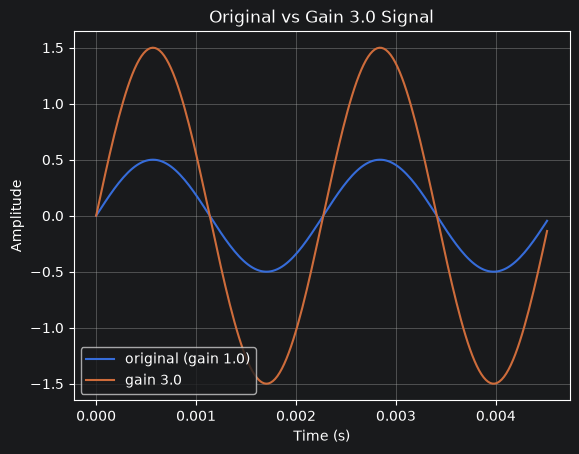

In [8]:
gain3 = 3.0 * x

plt.plot(t[:200], x[:200], label="original (gain 1.0)")
plt.plot(t[:200], gain3[:200], label="gain 3.0")
plt.legend()
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Original vs Gain 3.0 Signal")
plt.grid(True)
plt.show()

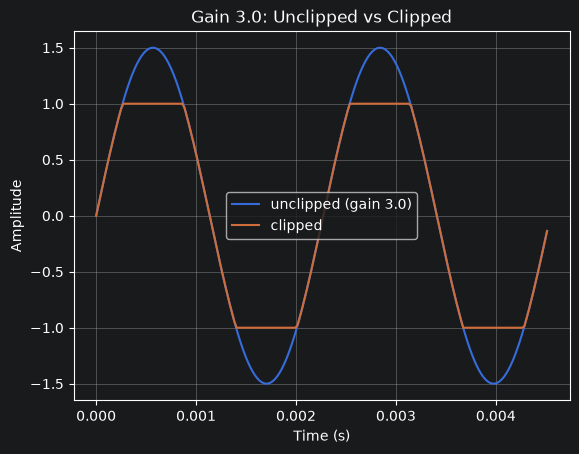

In [9]:
clipped = np.clip(gain3, -1, 1)

plt.plot(t[:200], gain3[:200], label="unclipped (gain 3.0)")
plt.plot(t[:200], clipped[:200], label="clipped")
plt.legend()
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Gain 3.0: Unclipped vs Clipped")
plt.grid(True)
plt.show()

## Activity B2: Mixing Two Audio Signals

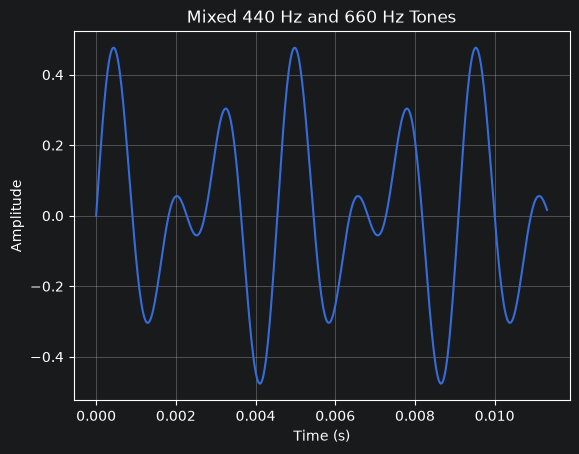

In [10]:
t = np.arange(fs) / fs
tone1 = 0.5 * np.sin(2 * np.pi * 440 * t)
tone2 = 0.5 * np.sin(2 * np.pi * 660 * t)

mixed = 0.5 * tone1 + 0.5 * tone2

plt.plot(t[:500], mixed[:500])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Mixed 440 Hz and 660 Hz Tones")
plt.grid(True)
plt.show()

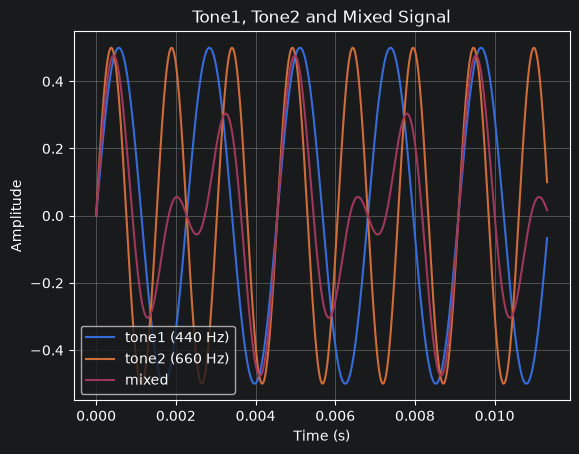

In [11]:
plt.plot(t[:500], tone1[:500], label="tone1 (440 Hz)")
plt.plot(t[:500], tone2[:500], label="tone2 (660 Hz)")
plt.plot(t[:500], mixed[:500], label="mixed")
plt.legend()
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Tone1, Tone2 and Mixed Signal")
plt.grid(True)
plt.show()

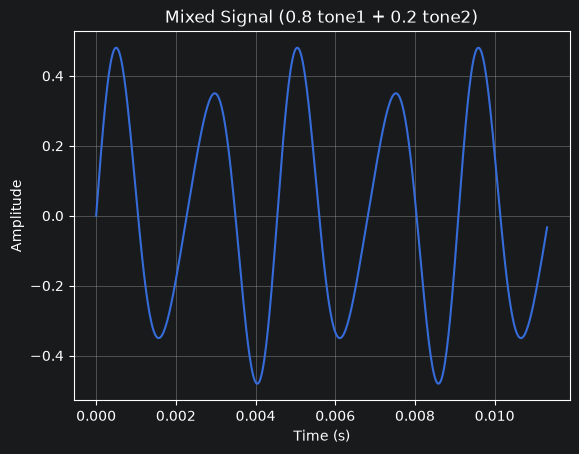

In [12]:
mixed2 = 0.8 * tone1 + 0.2 * tone2

plt.plot(t[:500], mixed2[:500])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Mixed Signal (0.8 tone1 + 0.2 tone2)")
plt.grid(True)
plt.show()

# Activity B3: Delay and Echo

In [20]:
duration = 2
t = np.arange(int(fs * duration)) / fs
x = 0.5 * np.sin(2 * np.pi * 440 * t)

delay_seconds = 0.25
delay_samples = int(delay_seconds * fs)

echo = x.copy()
echo[delay_samples:] += 0.7 * x[:-delay_samples]

print("Delay in samples:", delay_samples)

Delay in samples: 11025


# PART C: Image Point Processing
## Activity C1: Load and Inspect an Image

Shape: (414, 736, 3)
Data type: uint8
Minimum value: 0
Maximum value: 255


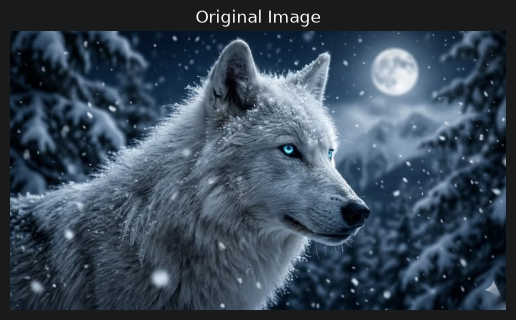

In [21]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img_pil = Image.open("image.jpg").convert("RGB")
img = np.array(img_pil)

print("Shape:", img.shape)
print("Data type:", img.dtype)
print("Minimum value:", img.min())
print("Maximum value:", img.max())

plt.imshow(img)
plt.axis("off")
plt.title("Original Image")
plt.show()

## Activity C2: Brightness Adjustment


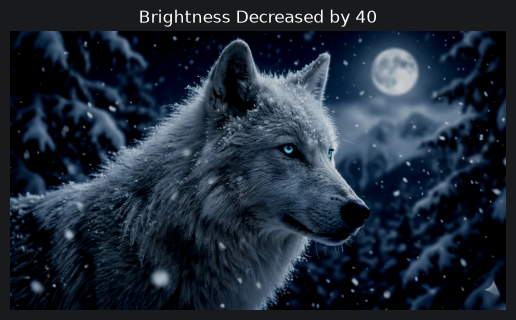

In [30]:
bright = np.clip(
 img.astype(np.int16) - 40,
 0,
 255
).astype(np.uint8)

plt.imshow(bright)
plt.axis("off")
plt.title("Brightness Decreased by 40")
plt.show()

In [31]:
pixel = img[100, 100]

print("Original RGB values:", pixel)

Original RGB values: [51 72 93]


## Activity C3: Image Negative

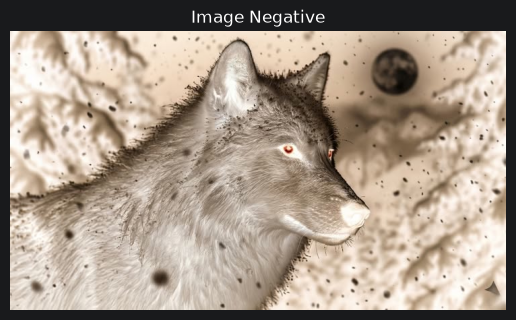

In [32]:
negative = 255 - img

plt.imshow(negative)
plt.axis("off")
plt.title("Image Negative")
plt.show()

## Activity C4: Grayscale and Thresholding

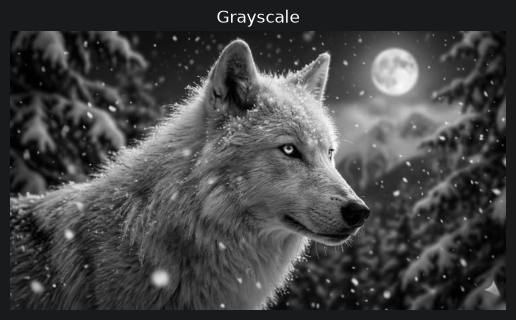

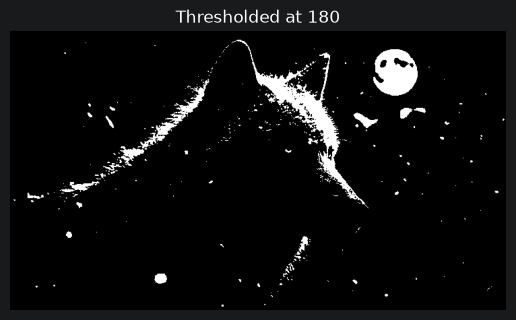

In [35]:
gray = np.array(img_pil.convert("L"))

threshold = 180

binary = np.where(gray >= threshold, 255, 0).astype(np.uint8)

plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.title("Grayscale")
plt.show()

plt.imshow(binary, cmap="gray")
plt.axis("off")
plt.title("Thresholded at 180")
plt.show()

# Part D: Image Neighbourhood Processing
## Activity D2: Smoothing with OpenCV

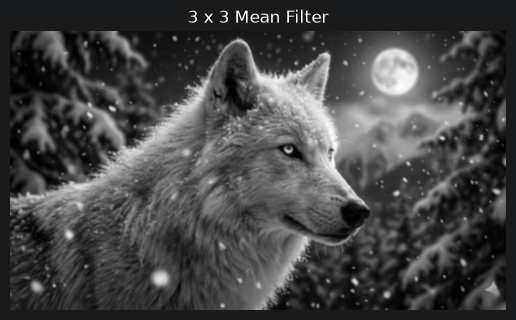

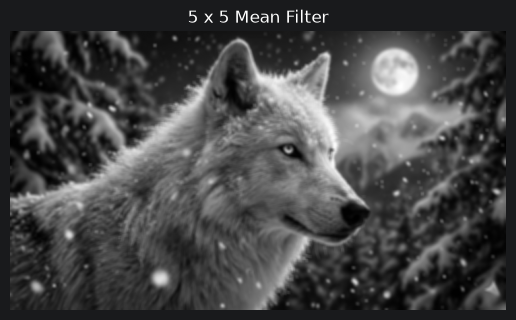

In [36]:
import cv2

gray_cv = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
smooth3 = cv2.blur(gray_cv, (3, 3))
smooth5 = cv2.blur(gray_cv, (5, 5))

plt.imshow(smooth3, cmap="gray")
plt.axis("off")
plt.title("3 x 3 Mean Filter")
plt.show()

plt.imshow(smooth5, cmap="gray")
plt.axis("off")
plt.title("5 x 5 Mean Filter")
plt.show()

## Activity D3: Sharpening by Convolution

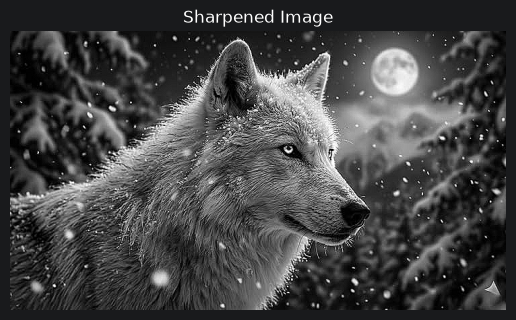

In [38]:
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(gray_cv, -1, kernel)

plt.imshow(sharpened, cmap="gray")
plt.axis("off")
plt.title("Sharpened Image")
plt.show()

# PART E: Digital Video Processing
## Activity E1: Inspect Video Properties

In [47]:
import cv2

cap = cv2.VideoCapture("input.mp4")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = frame_count / fps if fps else 0

print("FPS:", fps)
print("Resolution:", width, "x", height)
print("Frame count:", frame_count)
print("Approx. duration:", duration, "seconds")

FPS: 30.068203173439755
Resolution: 720 x 1280
Frame count: 882
Approx. duration: 29.333312499999998 seconds


## Activity E2: Extract and Process Frames

In [48]:
cap = cv2.VideoCapture("input.mp4")
frame_number = 0
saved = 0

while True:
    ok, frame = cap.read()
    if not ok:
        break

    if frame_number % 30 == 0 and saved < 5:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        cv2.imwrite(f"gray_frame_{saved}.jpg", gray)
        saved += 1

    frame_number += 1

cap.release()
print("Frames read:", frame_number)
print("Processed frames saved:", saved)

Frames read: 881
Processed frames saved: 5


In [50]:
cap = cv2.VideoCapture("input.mp4")
targets = [0, 30]   # pick any two of: 0, 30, 60, 90, 120
frame_number = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    if frame_number in targets:
        cv2.imwrite(f"color_frame_{frame_number}.jpg", frame)
    frame_number += 1
cap.release()
print("Done extracting color frames.")

Done extracting color frames.


## Activity E3: Resize a Video Frame

In [51]:
cap = cv2.VideoCapture("input.mp4")
ok, frame = cap.read()
cap.release()

if ok:
    resized = cv2.resize(frame, (1280, 720))
    cv2.imwrite("resized_frame.jpg", resized)
    print("Original:", frame.shape)
    print("Resized:", resized.shape)

Original: (1280, 720, 3)
Resized: (720, 1280, 3)


# PART F: Digital Audio Synthesis and Integration
## Activity F1: Synthesize Different Waveforms

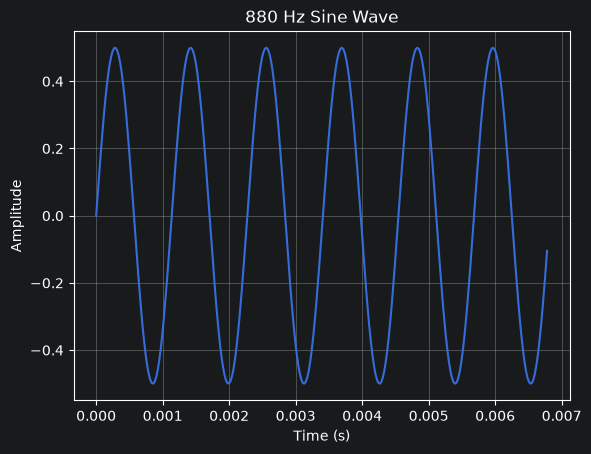

In [56]:
fs = 44100
t = np.arange(fs) / fs

sine = 0.5 * np.sin(2 * np.pi * 880 * t)

plt.plot(t[:300], sine[:300])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("880 Hz Sine Wave")
plt.grid(True)
plt.show()

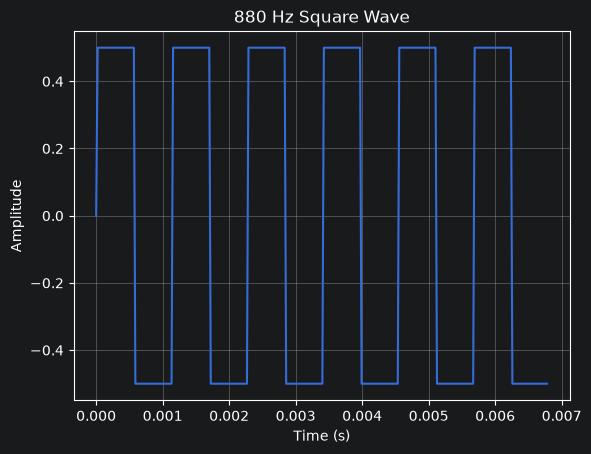

In [57]:
square = 0.5 * np.sign(np.sin(2 * np.pi * 880 * t))

plt.plot(t[:300], square[:300])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("880 Hz Square Wave")
plt.grid(True)
plt.show()

## Activity F2: Additive Synthesis

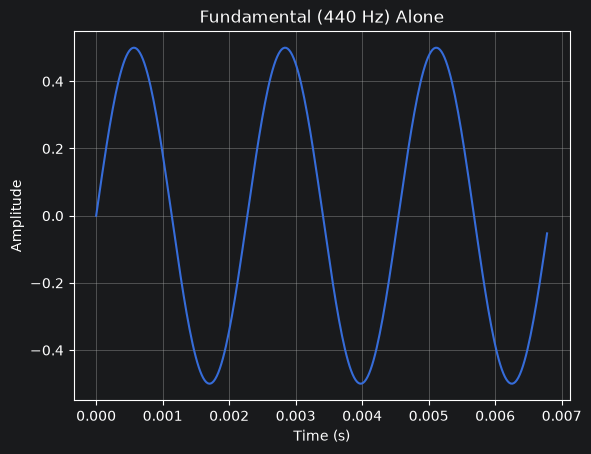

In [60]:
plt.plot(t[:300], fundamental[:300])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Fundamental (440 Hz) Alone")
plt.grid(True)
plt.show()

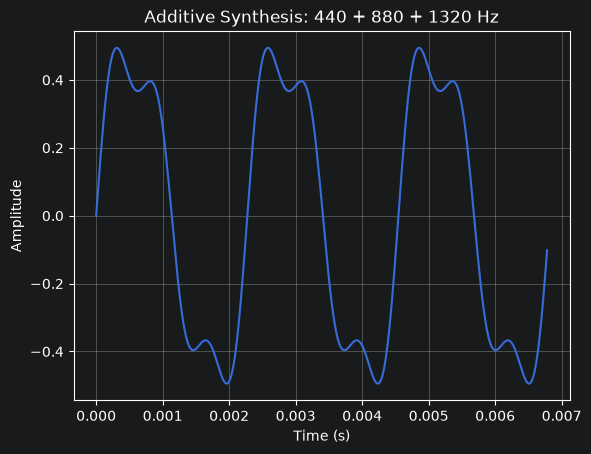

In [61]:
fundamental = 0.5 * np.sin(2*np.pi*440*t)
harmonic2 = 0.05 * np.sin(2*np.pi*880*t)
harmonic3 = 0.125 * np.sin(2*np.pi*1320*t)

additive = fundamental + harmonic2 + harmonic3

plt.plot(t[:300], additive[:300])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Additive Synthesis: 440 + 880 + 1320 Hz")
plt.grid(True)
plt.show()

## Activity F3: Simple ADSR Envelope

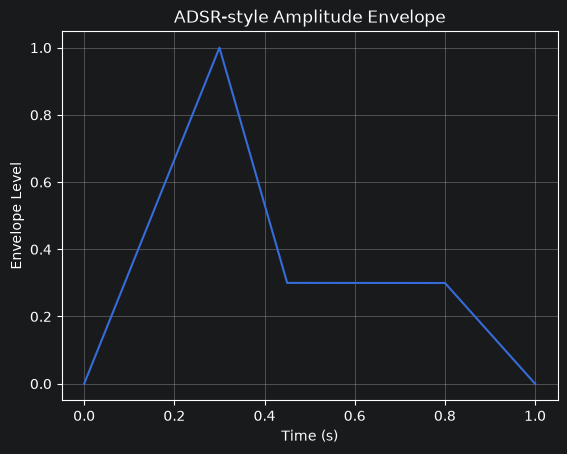

In [68]:
fs = 44100
duration = 1.0
t = np.arange(int(fs * duration)) / fs
tone = 0.5 * np.sin(2*np.pi*440*t)

attack = int(0.30 * fs)
decay = int(0.15 * fs)
release = int(0.20 * fs)
sustain_end = len(tone) - release

env = np.ones(len(tone))
env[:attack] = np.linspace(0, 1, attack)
env[attack:attack+decay] = np.linspace(1, 0.3, decay)
env[attack+decay:sustain_end] = 0.3
env[sustain_end:] = np.linspace(0.3, 0, release)

shaped = tone * env

plt.plot(t, env)
plt.xlabel("Time (s)")
plt.ylabel("Envelope Level")
plt.title("ADSR-style Amplitude Envelope")
plt.grid(True)
plt.show()

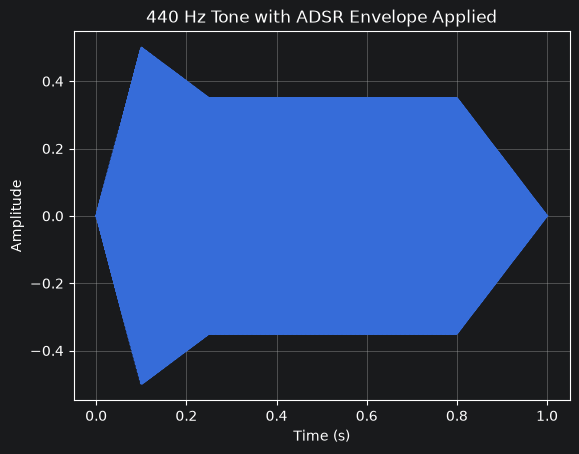

In [65]:
   plt.plot(t, shaped)
   plt.xlabel("Time (s)")
   plt.ylabel("Amplitude")
   plt.title("440 Hz Tone with ADSR Envelope Applied")
   plt.grid(True)
   plt.show()